In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from wordcloud import WordCloud

sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams['font.sans-serif'] = 'Arial'

In [2]:
data_path = "womens_clothing_classification_dataset.csv"
if not os.path.exists(data_path):
    data_path = os.path.join("29-10-2026", "Task 1", "womens_clothing_classification_dataset.csv")

df = pd.read_csv(data_path)
df['Full_Review_Text'] = df['Full_Review_Text'].fillna('')

pos_mask = df['Recommended IND'] == 1
neg_mask = df['Recommended IND'] == 0

pos_texts = df.loc[pos_mask, 'Full_Review_Text'].tolist()
neg_texts = df.loc[neg_mask, 'Full_Review_Text'].tolist()
print(f"Positive review count: {len(pos_texts)}, Negative review count: {len(neg_texts)}")

Positive review count: 19314, Negative review count: 4172


In [3]:
tfidf_vec = TfidfVectorizer(
    ngram_range=(1, 3),
    max_features=5000,
    stop_words='english',
    sublinear_tf=True
)

X_tfidf_all = tfidf_vec.fit_transform(df['Full_Review_Text'])
feature_names = np.array(tfidf_vec.get_feature_names_out())

X_tfidf_pos = tfidf_vec.transform(pos_texts)
X_tfidf_neg = tfidf_vec.transform(neg_texts)

mean_tfidf_pos = np.asarray(X_tfidf_pos.mean(axis=0)).ravel()
mean_tfidf_neg = np.asarray(X_tfidf_neg.mean(axis=0)).ravel()

df_terms = pd.DataFrame({
    'Term': feature_names,
    'TFIDF_Pos': mean_tfidf_pos,
    'TFIDF_Neg': mean_tfidf_neg,
    'TFIDF_Diff': mean_tfidf_pos - mean_tfidf_neg,
    'Distinctiveness': np.abs(mean_tfidf_pos - mean_tfidf_neg)
})

count_vec = CountVectorizer(vocabulary=feature_names, stop_words='english')
X_count_pos = count_vec.transform(pos_texts)
X_count_neg = count_vec.transform(neg_texts)
df_terms['Freq_Pos'] = np.asarray(X_count_pos.sum(axis=0)).ravel()
df_terms['Freq_Neg'] = np.asarray(X_count_neg.sum(axis=0)).ravel()
df_terms['Freq_Total'] = df_terms['Freq_Pos'] + df_terms['Freq_Neg']
df_terms['Ngram_Type'] = df_terms['Term'].apply(lambda x: 'Unigram' if len(x.split()) == 1 else ('Bigram' if len(x.split()) == 2 else 'Trigram'))

distinctiveness_threshold = np.percentile(df_terms['Distinctiveness'], 65)
freq_threshold = np.percentile(df_terms['Freq_Total'], 75)

df_terms['Is_Neutral'] = (df_terms['Distinctiveness'] < distinctiveness_threshold) & (df_terms['Freq_Total'] > freq_threshold)

df_neutral = df_terms[df_terms['Is_Neutral']].sort_values(by='Freq_Total', ascending=False).reset_index(drop=True)
display(df_neutral.head(10))

,Term,TFIDF_Pos,TFIDF_Neg,TFIDF_Diff,Distinctiveness,Freq_Pos,Freq_Neg,Freq_Total,Ngram_Type,Is_Neutral
0,loose,0.006409,0.006562,-0.000153,0.000153,1003,214,1217,Unigram,True
1,time,0.006401,0.006286,0.000115,0.000115,958,206,1164,Unigram,True
2,ve,0.006090,0.006100,-0.000010,0.000010,931,209,1140,Unigram,True
3,blouse,0.006299,0.006200,0.000098,0.000098,946,184,1130,Unigram,True
4,pattern,0.005884,0.006233,-0.000349,0.000349,851,198,1049,Unigram,True
5,print,0.005906,0.005804,0.000103,0.000103,840,178,1018,Unigram,True
6,went,0.005508,0.005283,0.000225,0.000225,823,156,979,Unigram,True
7,bra,0.005221,0.005280,-0.000058,0.000058,788,164,952,Unigram,True
8,lot,0.005203,0.004792,0.000410,0.000410,733,144,877,Unigram,True
9,received,0.005255,0.005534,-0.000279,0.000279,704,160,864,Unigram,True


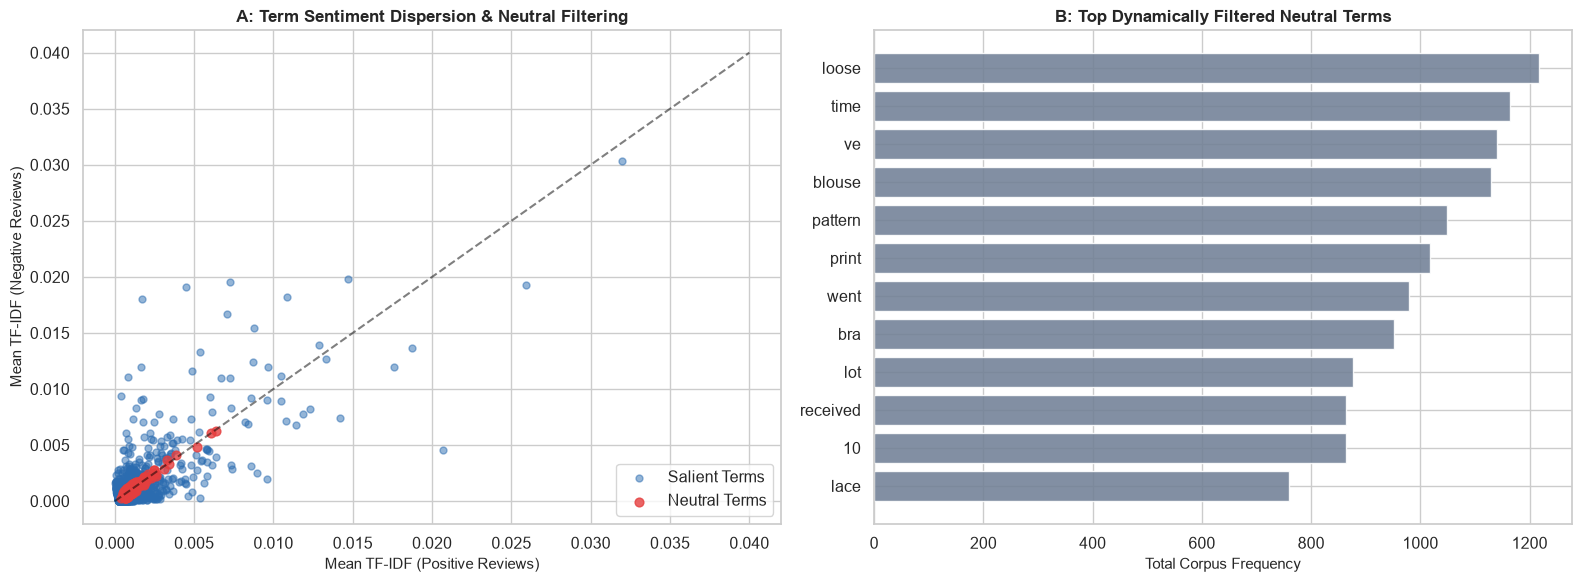

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sample_terms = df_terms.sample(n=min(2000, len(df_terms)), random_state=42)
axes[0].scatter(sample_terms.loc[~sample_terms['Is_Neutral'], 'TFIDF_Pos'], 
                sample_terms.loc[~sample_terms['Is_Neutral'], 'TFIDF_Neg'], 
                c='#2B6CB0', alpha=0.5, s=25, label='Salient Terms')
axes[0].scatter(sample_terms.loc[sample_terms['Is_Neutral'], 'TFIDF_Pos'], 
                sample_terms.loc[sample_terms['Is_Neutral'], 'TFIDF_Neg'], 
                c='#E53E3E', alpha=0.8, s=40, label='Neutral Terms')

axes[0].plot([0, 0.04], [0, 0.04], color='black', linestyle='--', alpha=0.5)
axes[0].set_title("A: Term Sentiment Dispersion & Neutral Filtering", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Mean TF-IDF (Positive Reviews)", fontsize=11)
axes[0].set_ylabel("Mean TF-IDF (Negative Reviews)", fontsize=11)
axes[0].legend(loc='lower right', frameon=True)

top_neutral_bar = df_neutral.head(12).sort_values(by='Freq_Total', ascending=True)
axes[1].barh(top_neutral_bar['Term'], top_neutral_bar['Freq_Total'], color='#718096', alpha=0.88)
axes[1].set_title("B: Top Dynamically Filtered Neutral Terms", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Total Corpus Frequency", fontsize=11)

plt.tight_layout()
plt.show()

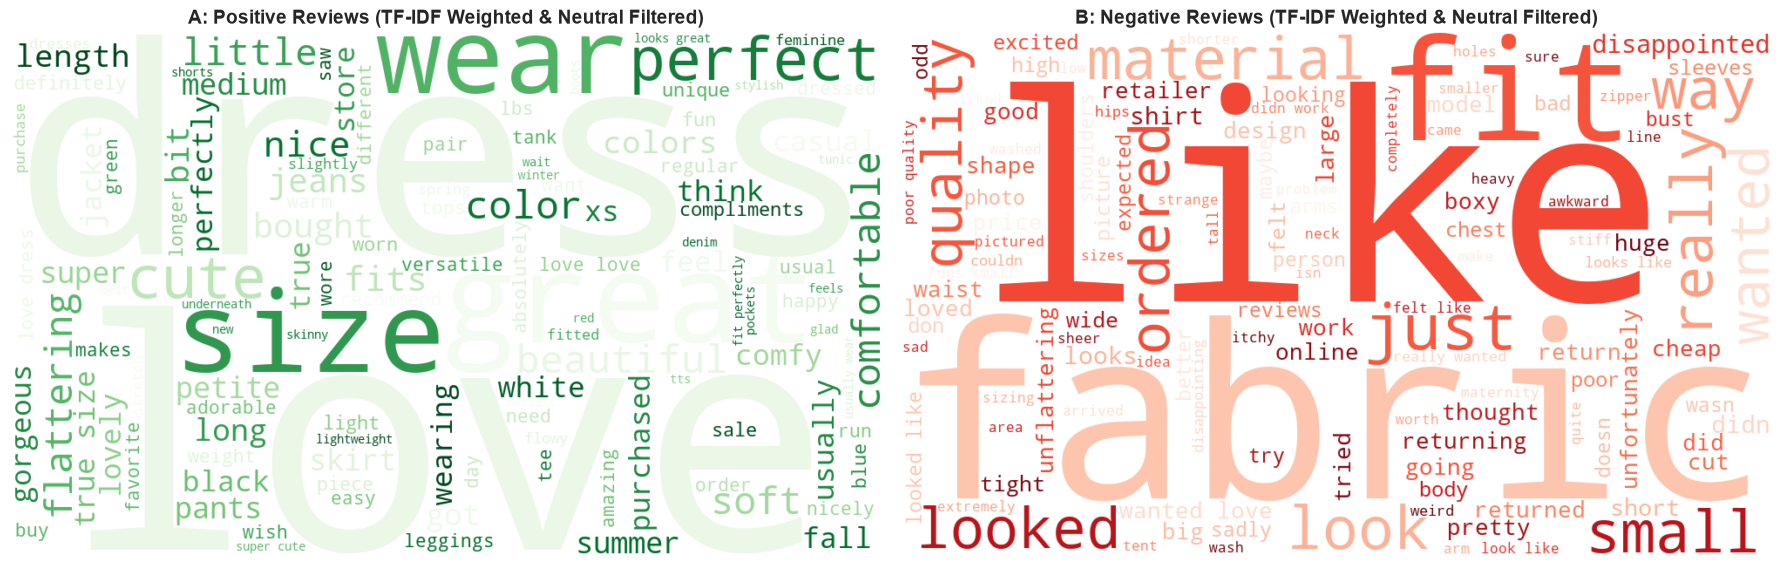

In [5]:
df_active = df_terms[~df_terms['Is_Neutral']].copy()

df_pos_top = df_active.sort_values(by='TFIDF_Diff', ascending=False).head(500).reset_index(drop=True)
df_neg_top = df_active.sort_values(by='TFIDF_Diff', ascending=True).head(500).reset_index(drop=True)

pos_weights = dict(zip(df_pos_top['Term'], df_pos_top['TFIDF_Pos']))
neg_weights = dict(zip(df_neg_top['Term'], df_neg_top['TFIDF_Neg']))

wc_pos = WordCloud(width=1000, height=600, background_color='white', colormap='Greens', max_words=120, random_state=42)
wc_pos.generate_from_frequencies(pos_weights)

wc_neg = WordCloud(width=1000, height=600, background_color='white', colormap='Reds', max_words=120, random_state=42)
wc_neg.generate_from_frequencies(neg_weights)

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
axes[0].imshow(wc_pos, interpolation='bilinear')
axes[0].axis('off')
axes[0].set_title("A: Positive Reviews (TF-IDF Weighted & Neutral Filtered)", fontsize=14, fontweight='bold')

axes[1].imshow(wc_neg, interpolation='bilinear')
axes[1].axis('off')
axes[1].set_title("B: Negative Reviews (TF-IDF Weighted & Neutral Filtered)", fontsize=14, fontweight='bold')

plt.tight_layout()
plt.show()

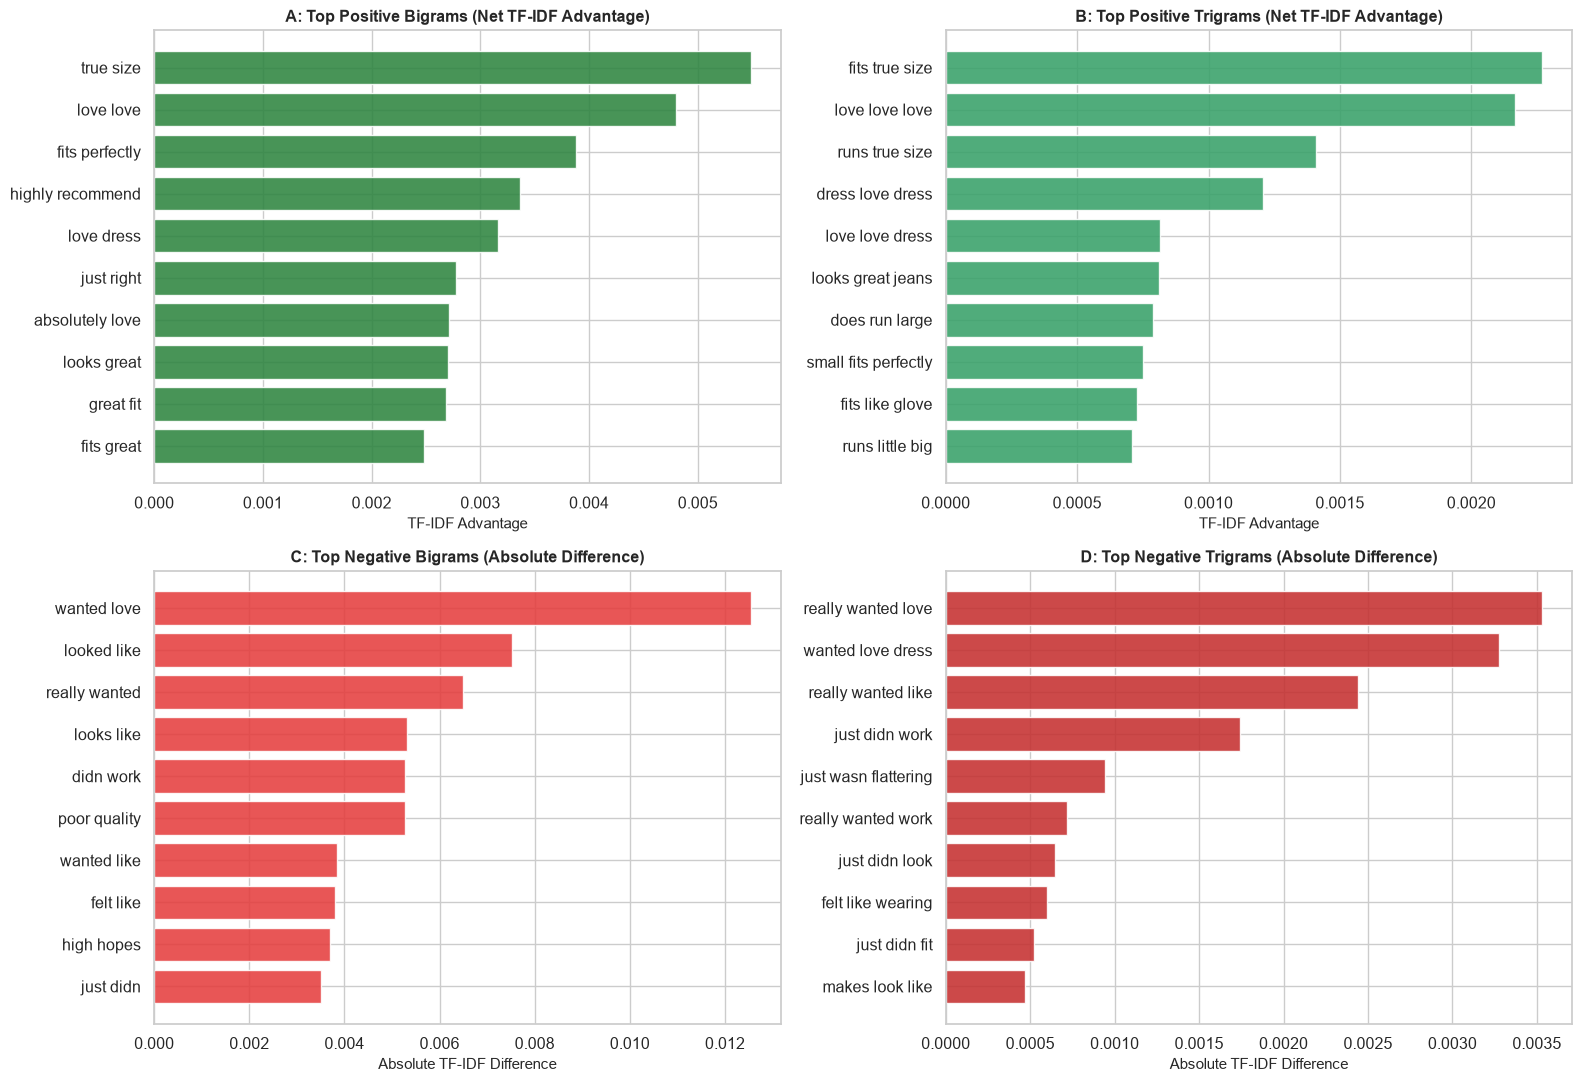

In [6]:
top_bigrams_pos = df_active[df_active['Ngram_Type'] == 'Bigram'].sort_values(by='TFIDF_Diff', ascending=False).head(10)
top_trigrams_pos = df_active[df_active['Ngram_Type'] == 'Trigram'].sort_values(by='TFIDF_Diff', ascending=False).head(10)

top_bigrams_neg = df_active[df_active['Ngram_Type'] == 'Bigram'].sort_values(by='TFIDF_Diff', ascending=True).head(10)
top_trigrams_neg = df_active[df_active['Ngram_Type'] == 'Trigram'].sort_values(by='TFIDF_Diff', ascending=True).head(10)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

axes[0, 0].barh(top_bigrams_pos.sort_values(by='TFIDF_Diff', ascending=True)['Term'], 
                top_bigrams_pos.sort_values(by='TFIDF_Diff', ascending=True)['TFIDF_Diff'], color='#2E8540', alpha=0.88)
axes[0, 0].set_title("A: Top Positive Bigrams (Net TF-IDF Advantage)", fontsize=11.5, fontweight='bold')
axes[0, 0].set_xlabel("TF-IDF Advantage", fontsize=10.5)

axes[0, 1].barh(top_trigrams_pos.sort_values(by='TFIDF_Diff', ascending=True)['Term'], 
                top_trigrams_pos.sort_values(by='TFIDF_Diff', ascending=True)['TFIDF_Diff'], color='#38A169', alpha=0.88)
axes[0, 1].set_title("B: Top Positive Trigrams (Net TF-IDF Advantage)", fontsize=11.5, fontweight='bold')
axes[0, 1].set_xlabel("TF-IDF Advantage", fontsize=10.5)

axes[1, 0].barh(top_bigrams_neg.sort_values(by='TFIDF_Diff', ascending=False)['Term'], 
                np.abs(top_bigrams_neg.sort_values(by='TFIDF_Diff', ascending=False)['TFIDF_Diff']), color='#E53E3E', alpha=0.88)
axes[1, 0].set_title("C: Top Negative Bigrams (Absolute Difference)", fontsize=11.5, fontweight='bold')
axes[1, 0].set_xlabel("Absolute TF-IDF Difference", fontsize=10.5)

axes[1, 1].barh(top_trigrams_neg.sort_values(by='TFIDF_Diff', ascending=False)['Term'], 
                np.abs(top_trigrams_neg.sort_values(by='TFIDF_Diff', ascending=False)['TFIDF_Diff']), color='#C53030', alpha=0.88)
axes[1, 1].set_title("D: Top Negative Trigrams (Absolute Difference)", fontsize=11.5, fontweight='bold')
axes[1, 1].set_xlabel("Absolute TF-IDF Difference", fontsize=10.5)

plt.tight_layout()
plt.show()

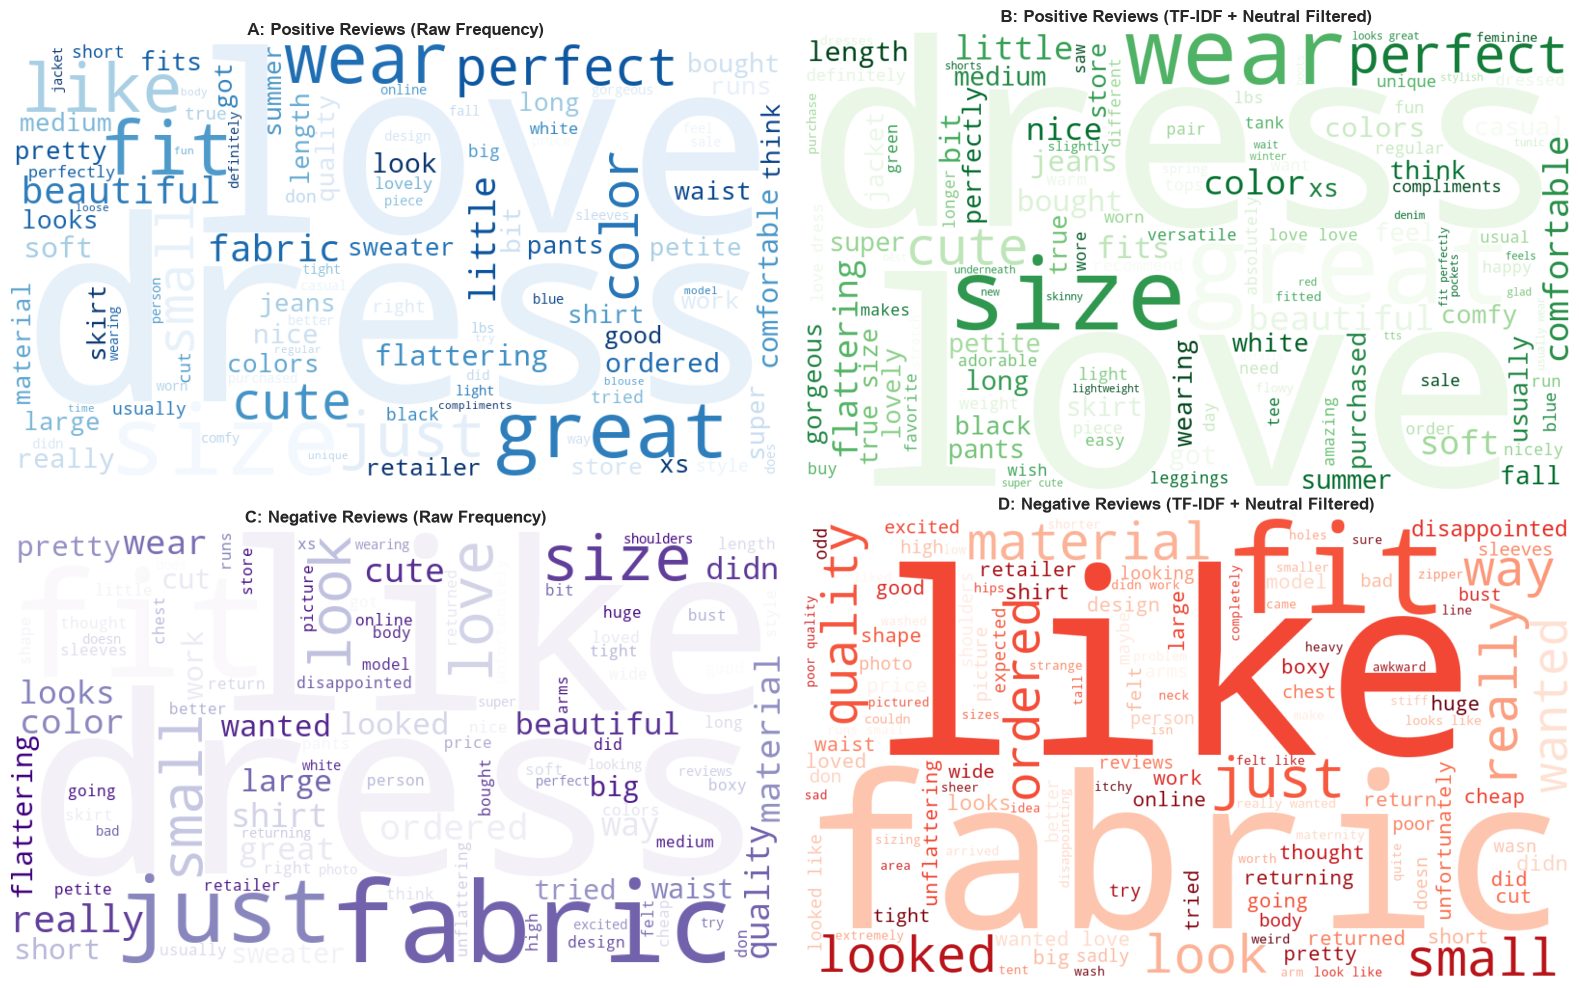

In [7]:
raw_pos_freq = dict(zip(df_terms['Term'], df_terms['Freq_Pos']))
raw_neg_freq = dict(zip(df_terms['Term'], df_terms['Freq_Neg']))

wc_raw_pos = WordCloud(width=800, height=450, background_color='white', colormap='Blues', max_words=100, random_state=42)
wc_raw_pos.generate_from_frequencies(raw_pos_freq)

wc_raw_neg = WordCloud(width=800, height=450, background_color='white', colormap='Purples', max_words=100, random_state=42)
wc_raw_neg.generate_from_frequencies(raw_neg_freq)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes[0, 0].imshow(wc_raw_pos, interpolation='bilinear')
axes[0, 0].axis('off')
axes[0, 0].set_title("A: Positive Reviews (Raw Frequency)", fontsize=12, fontweight='bold')

axes[0, 1].imshow(wc_pos, interpolation='bilinear')
axes[0, 1].axis('off')
axes[0, 1].set_title("B: Positive Reviews (TF-IDF + Neutral Filtered)", fontsize=12, fontweight='bold')

axes[1, 0].imshow(wc_raw_neg, interpolation='bilinear')
axes[1, 0].axis('off')
axes[1, 0].set_title("C: Negative Reviews (Raw Frequency)", fontsize=12, fontweight='bold')

axes[1, 1].imshow(wc_neg, interpolation='bilinear')
axes[1, 1].axis('off')
axes[1, 1].set_title("D: Negative Reviews (TF-IDF + Neutral Filtered)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()